# Context

This notebook was developed as a report of my work in the discipline of Video Coding, given by the professors, Ismael Seidel and José Luiz Almada Güntzel. 
It is about Light Fields, where I apply some estimatives of the objective metric Structural Similarity Index Measure (SSIM) comparing always with the real calculated values. 

In [1]:
from IPython.display import display
import json
import io
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from PIL import Image
import plotly.express as px
from skimage.metrics import mean_squared_error as mse
from skimage.util import crop
from scipy import ndimage, datasets
from scipy.ndimage import uniform_filter, gaussian_filter
from tqdm import tqdm
import sys
import yuvio
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({"axes.spines.top": False,
                     "axes.spines.right": False})

# Intro

Let's start by exploring the directories and looking for the reports from the decoded Light Fields (LF). In the next cells, I want to show the path to get each one.

In [2]:
# Here we can see some of the LFs decoded with lfctoolkit. These jsons contain different metrics for each LF, like SSIM, PSNR, ... 
# I will pass their names to access later with python
!ls ../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/ | head
!ls ../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/ > txt.txt

Bikes_015_vmaf_11_11_625x434_yuv444p10le.json
Bikes_03_vmaf_11_11_625x434_yuv444p10le.json
Bikes_12_vmaf_11_11_625x434_yuv444p10le.json
Bikes_3_vmaf_11_11_625x434_yuv444p10le.json
Bikes_96_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_015_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_03_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_12_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_3_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_96_vmaf_11_11_625x434_yuv444p10le.json


In [3]:
# this cell opens txt.txt, reads each line and pass each one for a list of names
path_jpeg = '../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/'

f = open('txt.txt', 'r')
texto = f.read()
all_LFs = texto.split('\n')
all_LFs = [i for i in all_LFs if i.endswith('.json')]
all_LFs[:10]

['Bikes_015_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_03_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_12_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_3_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_96_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_015_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_03_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_12_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_3_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_96_vmaf_11_11_625x434_yuv444p10le.json']

\
Here I store in the LightField_names variable just the name of each LF + its compress tax.

In [4]:
LightField_names = [lf.split('_vmaf')[0] for lf in all_LFs]
LightField_names[:10]

['Bikes_015',
 'Bikes_03',
 'Bikes_12',
 'Bikes_3',
 'Bikes_96',
 'Danger_de_Mort_015',
 'Danger_de_Mort_03',
 'Danger_de_Mort_12',
 'Danger_de_Mort_3',
 'Danger_de_Mort_96']

In [5]:
# Nessa célula eu obtenho todos os valores do PSNR_y e SSIM
# para cada view de cada LF, que foi rodada pelo lfctoolkit.
# PS: não sei como o SSIM foi calculado
ssim_dict_of_each_LF = {}
psnr_dict_of_each_LF = {}

for each_LF, LF_name in zip(all_LFs, LightField_names):
    ssim_list_of_each_view_per_LF = []
    psnr_list_of_each_view_per_LF = []
    
    # Lembrando path_jpeg = '../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/'
    path_corrigido = os.path.join(path_jpeg + each_LF)
    
    with open(path_corrigido) as f:
        
        for linha in f:  # 1 line is exactly like '         "integer_adm_scale0": 0.888848,'
            par = linha.strip()[:-1].split(': ')  # which par is ['"integer_adm_scale0"', '0.888848']

            try:
                if par[0] == '"float_ssim"':
                    ssim_list_of_each_view_per_LF.append(float(par[1]))
                elif par[0] == '"psnr_y"':
                    psnr_list_of_each_view_per_LF.append(float(par[1]))
                    
            except:
                continue
                
    ssim_dict_of_each_LF[LF_name] = ssim_list_of_each_view_per_LF
    psnr_dict_of_each_LF[LF_name] = psnr_list_of_each_view_per_LF

mean_psnr_y_bikes015 = np.mean(psnr_dict_of_each_LF['Bikes_015'])
print('mean_psnr_y_bikes015 ', mean_psnr_y_bikes015) # verified some cells bellow

mean_ssim_bikes015 = np.mean(ssim_dict_of_each_LF['Bikes_015'])
print('mean_ssim_bikes015 ', mean_ssim_bikes015) # verified some cells below
print('\nBikes_015:', psnr_dict_of_each_LF['Bikes_015'])

mean_psnr_y_bikes015  29.99465495041322
mean_ssim_bikes015  0.9303986280991735

Bikes_015: [28.208347, 29.35228, 29.814472, 29.902728, 29.893179, 29.921376, 30.004367, 30.047687, 29.970585, 29.569613, 28.223673, 29.405722, 30.265871, 30.43936, 30.42555, 30.370664, 30.336209, 30.334539, 30.337683, 30.255453, 30.093684, 29.274278, 29.712374, 30.140608, 30.440398, 30.53433, 30.424018, 30.351452, 30.342352, 30.353098, 30.406911, 30.364091, 29.869671, 30.016113, 30.334002, 30.271592, 30.257165, 30.281573, 30.2571, 30.306114, 30.502057, 30.513733, 30.077092, 29.62244, 29.516392, 30.032605, 30.460147, 30.341195, 30.139692, 30.153012, 30.229714, 30.208575, 30.185208, 30.292704, 30.080113, 30.131625, 30.36556, 30.257013, 30.251217, 30.209943, 30.079223, 30.06951, 30.285845, 30.412492, 29.979754, 29.466994, 29.50123, 29.893939, 30.333698, 30.32802, 30.122762, 30.07845, 30.176315, 30.30813, 30.365797, 30.451933, 30.129637, 30.084412, 30.509948, 30.499715, 30.40151, 30.259956, 30.21242, 30.26985, 

\
Quero fazer um DataFrame com todos os dados, ou seja, cujas linhas sejam cada Light Field com sua respectiva taxa, e cada coluna um valor do SSIM ou do PSNR_y de cada view. Como os LFs tem quantidades de views diferentes, vou completá-los com nulos pra terem as mesmas dimensões

In [6]:
ssim_df = pd.DataFrame.from_dict(ssim_dict_of_each_LF, orient = 'index')
ssim_df.columns = [f'view_{i}' for i in ssim_df.columns]

ssim_df['media'] = ssim_df.mean(axis = 1, skipna = True)
ssim_df['std'] = ssim_df.drop(columns=['media']).std(axis=1, skipna=True)
print(ssim_df.shape)
ssim_df.index.name = 'ssim'
ssim_df[['view_0', 'view_1', 'view_2', 'view_3', 'media']].head(10)

(45, 963)


,view_0,view_1,view_2,view_3,media
ssim,,,,,
Bikes_015,0.910789,0.920647,0.925464,0.926935,0.930399
Bikes_03,0.942292,0.953586,0.957116,0.957668,0.959361
Bikes_12,0.975320,0.983393,0.985195,0.985290,0.985855
Bikes_3,0.987100,0.991931,0.992668,0.992699,0.992880
Bikes_96,0.994603,0.996540,0.996669,0.996760,0.996798
Danger_de_Mort_015,0.887334,0.898359,0.902206,0.904826,0.907946
Danger_de_Mort_03,0.924960,0.941594,0.946611,0.947586,0.949744
Danger_de_Mort_12,0.966737,0.980839,0.983225,0.982586,0.983961
Danger_de_Mort_3,0.981647,0.990034,0.991154,0.990818,0.991486


Esse dataframe é o ssim de cada view de cada LF

\
Agora vou fazer o Data Frame pro PSNR e pro MSE, calculado diretamente do PSNR

In [7]:
psnr_df = pd.DataFrame.from_dict(psnr_dict_of_each_LF, orient = 'index')
psnr_df.columns = [f'view_{i}' for i in psnr_df.columns]
psnr_df.index.name = 'psnr'
psnr_df['media'] = psnr_df.mean(axis = 1, skipna = True)
psnr_df[['view_0', 'view_1', 'view_2', 'view_3', 'media']].head(5)

,view_0,view_1,view_2,view_3,media
psnr,,,,,
Bikes_015,28.208347,29.352280,29.814472,29.902728,29.994655
Bikes_03,30.197260,31.618555,31.987250,32.016086,32.119823
Bikes_12,34.184410,35.814774,36.120128,36.135778,36.374724
Bikes_3,36.974527,38.632188,38.895819,38.965575,39.213196
Bikes_96,40.737275,42.185595,42.278180,42.434652,42.693863


In [8]:
def MSE(original, pred):
    mse = np.mean(np.square(original.astype(np.float64) - pred.astype(np.float64)))
    return mse
    
def mse_from_psnr(psnr, b):
    mse = ((2**b -1)**2)/10**(psnr/10)
    return mse

In [9]:
mse_df = psnr_df.apply(mse_from_psnr, b = 10)
mse_df = mse_df.drop(columns = ['media'])
mse_df.index.name = 'mse'
mse_df['media'] = mse_df.mean(axis = 1, skipna = True)
mse_df[['view_0', 'view_1', 'view_2', 'view_3', 'media']].head()

,view_0,view_1,view_2,view_3,media
mse,,,,,
Bikes_015,1580.944294,1214.851705,1092.204766,1070.233319,1060.074924
Bikes_03,1000.058182,720.934431,662.256558,657.873916,650.640887
Bikes_12,399.310074,274.330356,255.704557,254.784772,244.309264
Bikes_3,210.038335,143.394491,134.948906,132.798683,127.052338
Bikes_96,88.312823,63.269116,61.934590,59.742868,56.839574


Pra verificar se fiz corretamente, podemos ver no json do `Bikes_015` que tanto a média do PSNR_y quanto o SSIM batem com o valor dos dfs

In [10]:
# !cd ../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/\
# && tail -n 34 Bikes_015_vmaf_11_11_625x434_yuv444p10le.json\
# | head -n 5\
# && tail -n 16 Bikes_015_vmaf_11_11_625x434_yuv444p10le.json\
# | head -n 5

---


In [11]:
# !cd ../lfctest/ce/results/jplm_ssim_estimate_results/ && echo */logs/*.json

In [12]:
_ = 'Bikes/logs/Bikes_015_11_11_625x434_PGX.json Bikes/logs/Bikes_03_11_11_625x434_PGX.json Bikes/logs/Bikes_12_11_11_625x434_PGX.json Bikes/logs/Bikes_3_11_11_625x434_PGX.json Bikes/logs/Bikes_96_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_015_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_03_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_12_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_3_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_96_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_015_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_03_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_12_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_3_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_96_11_11_625x434_PGX.json greek/logs/greek_005_9_9_512x512_PGX.json greek/logs/greek_0075_9_9_512x512_PGX.json greek/logs/greek_015_9_9_512x512_PGX.json greek/logs/greek_03_9_9_512x512_PGX.json greek/logs/greek_12_9_9_512x512_PGX.json set2/logs/set2_005_33_11_1920x1080_PGX.json set2/logs/set2_0075_33_11_1920x1080_PGX.json set2/logs/set2_015_33_11_1920x1080_PGX.json set2/logs/set2_03_33_11_1920x1080_PGX.json set2/logs/set2_12_33_11_1920x1080_PGX.json sideboard/logs/sideboard_015_9_9_512x512_PGX.json sideboard/logs/sideboard_03_9_9_512x512_PGX.json sideboard/logs/sideboard_12_9_9_512x512_PGX.json sideboard/logs/sideboard_3_9_9_512x512_PGX.json sideboard/logs/sideboard_96_9_9_512x512_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_015_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_03_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_12_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_3_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_96_11_11_625x434_PGX.json tarot/logs/tarot_005_17_17_1024x1024_PGX.json tarot/logs/tarot_0075_17_17_1024x1024_PGX.json tarot/logs/tarot_015_17_17_1024x1024_PGX.json tarot/logs/tarot_03_17_17_1024x1024_PGX.json tarot/logs/tarot_12_17_17_1024x1024_PGX.json'
LFs = _.split(' ')

path_lfc = '../lfctest/ce/results/jplm_ssim_estimate_results/'

LFs[:5]

['Bikes/logs/Bikes_015_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_03_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_12_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_3_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_96_11_11_625x434_PGX.json']

In [13]:
# Nessa célula eu coleto o SSIM estimado para os LFs, no geral, e não por view.
ssim_estimados_dict_por_lf = {}

for lf in LFs:

    path_corrigido = os.path.join(path_lfc + lf)     
    lf_nome = '_'.join(lf.split('/')[2].split('_')[:-4]) # Lembrando que cada lf é um elemento
    # da celula anterior. Ex: 'Bikes/logs/Bikes_03_11_11_625x434_PGX.json'
    # print(lf_nome_lista) retorna ['Bikes', '015']
    

        
    with open(path_corrigido, 'r') as f:
        
        for line in f:
            par = line.strip().split(': ')  # ['"est_ssim"', '0.9830602176303537']
            
            try:
                ssim_estimados_dict_por_lf[lf_nome] = float(par[1])
            
            except:
                continue

ssim_estimados_df = pd.DataFrame(ssim_estimados_dict_por_lf, index = ['ssim_estimados_dict_por_lf']).T
ssim_estimados_df.columns = ['ssim_estimado']
ssim_estimados_df.head()

,ssim_estimado
Bikes_015,0.983060
Bikes_03,0.989592
Bikes_12,0.996093
Bikes_3,0.997971
Bikes_96,0.999095


In [14]:
df_merged = pd.concat([ssim_estimados_df, ssim_df[['media']]], axis=1, join='outer')
df_merged.columns = ['ssim_estimado', 'ssim_original']
df_merged.head()

,ssim_estimado,ssim_original
Bikes_015,0.983060,0.930399
Bikes_03,0.989592,0.959361
Bikes_12,0.996093,0.985855
Bikes_3,0.997971,0.992880
Bikes_96,0.999095,0.996798


---

# Estimações de SSIM para Light Field

A partir daqui, vou implementar estimações de SSIM que desenvolvi para reproduzir os dados do luc e da martini no outro notebook. Algumas alterações serão feitas para incluir o formato dos LFs.

Como eu desenvolvi muitas das funções para compressão de imagem usando MSE em outro notebook, e aqui eu já tenho o $PSNR_y$ de cada view, apenas vou transformar o PSNR em MSE usando a relação de MSE em função de PSNR:


$$
MSE = \frac{(2^b-1)^2}{10^{\text{PSNR}/10}}
$$

A primeira equação de estimação do SSIM, deduzida pela Maria Martini é 

$$
SSIM \approx 1-\frac{MSE_l}{(2\sigma_x^2 + c_2)}
$$

onde tanto $MSE_l$ quanto $\sigma_x^2$ são locais. O próximo passado dos autores no paper é estimar o valor de $MSE_l$ com outras estatísticas. Pra isso, primeiro eles atribuem um parâmetro livre $\beta$. Que aqui será calculado como $0.5$, em decorrência da aproximação feita no paper, e depois tentatei estimar um valor mais adequado para LFs.

A primeira equação de estimação pro $MSE_l$ com o $\beta$ fica:

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

onde $\epsilon\ =\ 1e^{-6}$

Para a aproximação feita no paper, $\beta \approx 0.5$, a variância se tornar o desvio padrão:

$$MSE_l \approx MSE_G \frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}$$

Trocando na equação inicial, fica:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}
$$

E o SSIM global é calculado pela média de todas as janelas do frame da imagem original.

$$
MSSIM(X, Y) \approx \frac{1}{M}\sum_j \left ( 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]} \right)
$$

\
Vou começar com o Bikes. Na célula a seguir, vamos os light fields decodados. 

In [15]:
# !ls  ../lfctest/ce/results/jplm_ssim_estimate_results/Bikes/decoded/yuv/

\
A seguir está a nova função de estimar a ssim a partir da $MSE_G$ para light fields. Detalhe, global aqui quer dizer por view. Como visto antes, a MSE foi obtida do PSNR, que foi calculado usando a view inteira. Já a variância da imagem original também não foi usada. Como a martini diz no seu paper, a variância é uma das medidas que muda pouco para compressão via DCT. Nesse sentido, usei a variância local de cada view decodada.

Logo, será a implementação da seguinte função:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}
$$

In [16]:
def calcular_ssim_por_lf(funcao_ssim_lf, LFs, filtro = 'uniform', beta = 0.5):

    ssim_dict = {}

    for path_lf in tqdm(LFs, file=sys.stdout):

        elements = path_lf.split('_')
        nome = '_'.join(elements[:-4])
        n1, n2 = elements[-2].split('x')
        
        path_raw_lf = path_raw +  '_'.join(elements[:-5]) + '_' + '_'.join(elements[-4:])
        path = path_dir_yuv + path_lf
        
        LF_o = yuvio.mimread(path_raw_lf, int(n1), int(n2), 'yuv444p10le') # Original
        LF_r = yuvio.mimread(path, int(n1), int(n2), 'yuv444p10le') # Reconstruído

        ssim_lista = []
    
        for i in range(len(LF_r)):

            view_o = LF_o[i].y
            view_r = LF_r[i].y

            mse_g = MSE(view_o, view_r)
            ssim_lista.append(funcao_ssim_lf(view_o = view_o, view_r = view_r, mse_g = mse_g, filtro = filtro, beta = beta))

        ssim_dict[nome] = ssim_lista

    df = pd.DataFrame.from_dict(ssim_dict, orient = 'index')
    
    return df

## Implementando a SSIM do Luc

In [17]:
def ssim_luc_lf(view_o, view_r, win_size=7, b=10, k1=0.01, k2=0.03, mse_g = np.nan, filtro = 'uniform', beta = ''):
    '''
    Objective: Calculates the view_o SSIM, with the Gaussian and Uniform filters.
    To use the Gaussian, only need the radius, and sigma. To use the uniform filter, only needs the window size.
    Inputs necessary: Original and view_ronstructed images and the filter used.
    Returns: the mean of the SSIM for the whole image. a float value'''
    data_range = 2**b - 1
    c1 = (k1 * data_range) ** 2
    c2 = (k2 * data_range) ** 2

    view_o = view_o.astype(np.float64, copy=False)
    view_r = view_r.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    if filtro == 'uniform':
        # Local means
        ux = uniform_filter(view_o, size=win_size)
        uy = uniform_filter(view_r, size=win_size)
    
        # Local second moments
        uxx = uniform_filter(view_o * view_o, size=win_size)
        uyy = uniform_filter(view_r * view_r, size=win_size)
        uxy = uniform_filter(view_o * view_r, size=win_size)

    elif filtro == 'gaussian':
        # Local means
        ux = gaussian_filter(view_o, radius=5, sigma = 1.5)
        uy = gaussian_filter(view_r, radius=5, sigma = 1.5)

        # Local second moments
        uxx = gaussian_filter(view_o * view_o, radius=5, sigma = 1.5)
        uyy = gaussian_filter(view_r * view_r, radius=5, sigma = 1.5)
        uxy = gaussian_filter(view_o * view_r, radius=5, sigma = 1.5)
    
    # Local variances and covariance
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)
    vy = np.maximum(cov_norm * (uyy - uy * uy), 0.0)
    vxy = cov_norm * (uxy - ux * uy)

    # SSIM formula
    A1 = 2 * ux * uy + c1
    A2 = 2 * vxy + c2   
    B1 = ux**2 + uy**2 + c1
    B2 = vx + vy + c2

    # Local SSIM
    S = (A1 * A2) / (B1 * B2)

    pad = (win_size - 1) // 2
    # Global SSIM (excluding borders)
    return crop(S, pad).mean(dtype=np.float64)

In [18]:
d = {
    'Bikes': ['Bikes_015_11_11_625x434_yuv444p10le.yuv', 'Bikes_03_11_11_625x434_yuv444p10le.yuv', 'Bikes_12_11_11_625x434_yuv444p10le.yuv', 'Bikes_3_11_11_625x434_yuv444p10le.yuv', 'Bikes_96_11_11_625x434_yuv444p10le.yuv'],
    'Danger_de_Mort': ['Danger_de_Mort_015_11_11_625x434_yuv444p10le.yuv', 'Danger_de_Mort_03_11_11_625x434_yuv444p10le.yuv', 'Danger_de_Mort_12_11_11_625x434_yuv444p10le.yuv',  'Danger_de_Mort_3_11_11_625x434_yuv444p10le.yuv', 'Danger_de_Mort_96_11_11_625x434_yuv444p10le.yuv'],
    'Fountain_Vincent2': ['Fountain_Vincent2_015_11_11_625x434_yuv444p10le.yuv', 'Fountain_Vincent2_03_11_11_625x434_yuv444p10le.yuv', 'Fountain_Vincent2_12_11_11_625x434_yuv444p10le.yuv', 'Fountain_Vincent2_3_11_11_625x434_yuv444p10le.yuv', 'Fountain_Vincent2_96_11_11_625x434_yuv444p10le.yuv'],
    'greek': ['greek_005_9_9_512x512_yuv444p10le.yuv', 'greek_0075_9_9_512x512_yuv444p10le.yuv', 'greek_015_9_9_512x512_yuv444p10le.yuv', 'greek_03_9_9_512x512_yuv444p10le.yuv', 'greek_12_9_9_512x512_yuv444p10le.yuv'],
    # 'set2': ['set2_03_33_11_1920x1080_yuv444p10le.yuv', 'set2_005_33_11_1920x1080_yuv444p10le.yuv', 'set2_12_33_11_1920x1080_yuv444p10le.yuv', 'set2_015_33_11_1920x1080_yuv444p10le.yuv',  'set2_0075_33_11_1920x1080_yuv444p10le.yuv'],
}

In [19]:
try:
    open('drey.txt')
    path_raw = '../lfctest/ce/RAW/lightfields/YUV/serpentine/'
except:
    path_raw = '/home/andrey/lfctest/ce/RAW/lightfields/YUV/serpentine/'

In [20]:
dfs = []

for lf_nome, LFs in d.items():
    path_dir_yuv = f'../lfctest/ce/results/jplm_ssim_estimate_results/{lf_nome}/decoded/yuv/'
    df = calcular_ssim_por_lf(ssim_luc_lf, LFs = LFs)
    dfs.append(df)

ssim_luc = pd.concat(dfs)
ssim_luc['media'] = ssim_luc.mean(axis = 1, skipna = True)
ssim_luc['std'] = ssim_luc.drop(columns=['media']).std(axis=1, skipna=True)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:12<00:00,  2.45s/it]


In [41]:
ssim_luc.head(10)

,0,1,2,3,4,5,6,7,8,9,...,113,114,115,116,117,118,119,120,media,std
Bikes_015,0.833261,0.843869,0.849586,0.851510,0.851587,0.851269,0.852628,0.852940,0.850964,0.844104,...,0.849987,0.849801,0.850235,0.851545,0.852620,0.853108,0.849361,0.831146,0.856731,0.009920
Bikes_03,0.878419,0.893598,0.898632,0.899457,0.898684,0.898020,0.899715,0.901099,0.899888,0.892617,...,0.895958,0.895913,0.896474,0.897845,0.899560,0.899683,0.892241,0.865700,0.902783,0.010076
Bikes_12,0.931933,0.948156,0.951973,0.952142,0.951989,0.951952,0.953163,0.954209,0.953531,0.948806,...,0.948659,0.949937,0.950833,0.951511,0.951406,0.950361,0.944465,0.918827,0.954521,0.008142
Bikes_3,0.956737,0.969389,0.971495,0.971523,0.971507,0.971416,0.972143,0.972629,0.972171,0.969642,...,0.969024,0.969844,0.970565,0.970758,0.970256,0.969179,0.965931,0.947554,0.972731,0.005507
Bikes_96,0.977142,0.984396,0.984834,0.984973,0.985110,0.985155,0.985271,0.985360,0.984912,0.984686,...,0.983596,0.984386,0.984817,0.984603,0.983899,0.983217,0.982241,0.972792,0.985689,0.002761
Danger_de_Mort_015,0.802011,0.810395,0.813805,0.817554,0.820145,0.819492,0.819124,0.819386,0.819610,0.814863,...,0.820558,0.813002,0.808874,0.809373,0.811386,0.809531,0.793821,0.756392,0.821635,0.012713
Danger_de_Mort_03,0.855203,0.872517,0.878255,0.880150,0.881410,0.882134,0.883116,0.882638,0.880534,0.874859,...,0.880166,0.876528,0.873661,0.873631,0.874625,0.874120,0.860533,0.817946,0.883431,0.013920
Danger_de_Mort_12,0.920665,0.942662,0.946870,0.946512,0.948305,0.950207,0.950703,0.950391,0.949595,0.946725,...,0.945546,0.946323,0.946506,0.945686,0.944507,0.944992,0.939565,0.902515,0.949972,0.011154
Danger_de_Mort_3,0.947994,0.965184,0.967779,0.967432,0.968441,0.969744,0.970235,0.970112,0.969776,0.968288,...,0.966006,0.967426,0.967943,0.967757,0.966652,0.966072,0.964272,0.939870,0.970031,0.007463
Danger_de_Mort_96,0.973613,0.982174,0.982949,0.983144,0.983449,0.983810,0.983999,0.984117,0.984218,0.983806,...,0.981755,0.982791,0.983416,0.983443,0.982985,0.982111,0.981633,0.971698,0.984429,0.003371


In [21]:
dfs = []

for lf_nome, LFs in d.items():
    path_dir_yuv = f'../lfctest/ce/results/jplm_ssim_estimate_results/{lf_nome}/decoded/yuv/'
    df = calcular_ssim_por_lf(ssim_luc_lf, LFs = LFs, filtro = 'gaussian')
    dfs.append(df)

ssim_gaussian = pd.concat(dfs)
ssim_gaussian['media'] = ssim_gaussian.mean(axis = 1, skipna = True)
ssim_gaussian['std'] = ssim_gaussian.drop(columns=['media']).std(axis=1, skipna=True)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:14<00:00,  2.84s/it]


## Implementando a estimação da Martini

A equação a ser implementada é

$$SSIM \approx 1-\frac{MSE_l}{(2\sigma_x^2 + c_2)}$$

In [22]:
def ssim_martini_lf(view_o, view_r, mse_g, win_size=7, b=10, k1=0.01, k2=0.03, filtro = '', beta = ''):
    '''
    Objective: Calculates the estimated SSIM, with the Martini estimation.
    Returns: the mean of the SSIM for the whole image. A float value'''
    data_range = 2**b - 1
    c1 = (k1 * data_range) ** 2
    c2 = (k2 * data_range) ** 2

    view_o = view_o.astype(np.float64, copy=False)
    view_r = view_r.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    # Local means
    ux = uniform_filter(view_o, size=win_size)
    uy = uniform_filter(view_r, size=win_size)

    # Local second moments
    uxx = uniform_filter(view_o * view_o, size=win_size)
    
    # Local variances and covariance
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    mse_l =  np.maximum(uniform_filter((view_o - view_r) ** 2, size=win_size), 0.0)

    S = 1 - mse_l/ (2*vx + c2)

    pad = (win_size - 1) // 2

    return crop(S, pad).mean(dtype=np.float64)

In [23]:
dfs = []

for lf_nome, LFs in d.items():
    path_dir_yuv = f'../lfctest/ce/results/jplm_ssim_estimate_results/{lf_nome}/decoded/yuv/'
    df = calcular_ssim_por_lf(ssim_martini_lf, LFs = LFs)
    dfs.append(df)

ssim_martini = pd.concat(dfs)
ssim_martini['media'] = ssim_martini.mean(axis = 1, skipna = True)
ssim_martini['std'] = ssim_martini.drop(columns=['media']).std(axis=1, skipna=True)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:07<00:00,  1.48s/it]


## Implementando com $MSE_G$

Lembrando que a equação a ser implementada é

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}
$$

In [24]:
def ssim_global_lf(view_o, mse_g, view_r = 0, win_size = 7, b=10, k1=.01, k2=.03, filtro = '', beta = ''):
    '''
    Objective: Calculate the SSIM based on the global MSE of the view_original and reconstructed images.
    Inputs necessary: Original image and Global MSE.
    Returns: the mean of the SSIM for the whole image.'''
    data_range = 2**b - 1
    c2 = (k2*data_range)**2

    view_o = view_o.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    ux = ndimage.uniform_filter(view_o, size=win_size)
    uxx = ndimage.uniform_filter(view_o * view_o, size=win_size)
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    pad = (win_size - 1) // 2
    vx_c = crop(vx, pad)

    mssim = np.mean(1 - mse_g / (2*vx_c + c2))

    return mssim

In [25]:
dfs = []

for lf_nome, LFs in d.items():
    path_dir_yuv = f'../lfctest/ce/results/jplm_ssim_estimate_results/{lf_nome}/decoded/yuv/'
    df = calcular_ssim_por_lf(ssim_global_lf, LFs = LFs)
    dfs.append(df)

ssim_global = pd.concat(dfs)
ssim_global['media'] = ssim_global.mean(axis = 1, skipna = True)
ssim_global['std'] = ssim_global.drop(columns=['media']).std(axis=1, skipna=True)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:04<00:00,  1.14it/s]


## Implementação com a $MSE_l$ estimada com $\beta = 0.5$

A equação a ser implementada é

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

In [26]:
def ssim_beta_lf(view_o, mse_g, view_r = 0, win_size=7, b = 10, k1=.01, k2=.03, filtro = '', beta = 0.5):
    data_range = 2**b - 1

    c2 = (k2*data_range)**2

    view_o = view_o.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    ux = ndimage.uniform_filter(view_o, size=win_size)
    uxx = ndimage.uniform_filter(view_o * view_o, size=win_size)
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    pad = (win_size - 1) // 2
    vx_c = crop(vx, pad)

    epsilon = 1e-6
    vx_epsilon_beta = (vx_c + epsilon)**beta
    valor_esperado = np.mean(vx_epsilon_beta)
    mse_l = (mse_g/valor_esperado)*vx_epsilon_beta
    
    mssim = np.mean(1 - mse_l / (2*vx_c + c2))   # média de razões (a sua, sem bordas)

    return mssim

In [27]:
dfs = []

for lf_nome, LFs in d.items():
    path_dir_yuv = f'../lfctest/ce/results/jplm_ssim_estimate_results/{lf_nome}/decoded/yuv/'
    df = calcular_ssim_por_lf(ssim_beta_lf, LFs = LFs)
    dfs.append(df)

ssim_beta050 = pd.concat(dfs)
ssim_beta050.index.name = 'beta050'
ssim_beta050['media'] = ssim_beta050.mean(axis = 1, skipna = True)
ssim_beta050['std'] = ssim_beta050.drop(columns=['media']).std(axis=1, skipna=True)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


In [28]:
# Corrigindo o index da ssim_df
ssim_df.columns = list(range(ssim_df.shape[1] - 2)) + ['media', 'std']

## Resultados: Comparando Implementações e erros relativos

In [29]:
def comparar_implementacoes(dfs, colors, labels, nome_lfs, i, f, txs=[1.5, 3, 12, 30, 96], ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 4))

    for df, color, label in zip(dfs, colors, labels):
        ax.errorbar(txs, df.iloc[i:f]['media'], df.iloc[i:f]['std'], fmt='-o', color=color, label=label)
        # print(df.iloc[i:f].index)
    ax.legend()
    ax.set_xscale('log')
    ax.set_xlim([0, max(txs) + 5])
    ax.set_title(nome_lfs, loc='left')
    ax.set_xticks(txs)
    ax.set_xticklabels(txs)
    ax.set_xlabel('Taxa de compressão')
    ax.set_ylabel('MSSIM')
    return ax

    
def comparando_erros(dfs_erro, labels, colors, i, f, txs=[1.5, 3, 12, 30, 96], ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    for df, color, label in zip(dfs_erro, colors, labels):
        erro_media = ((ssim_df.iloc[i:f] - df.iloc[i:f]) / ssim_df.iloc[i:f]).mean(axis=1, skipna=True) * 100
        erro_std = ((ssim_df.iloc[i:f] - df.iloc[i:f]) / ssim_df.iloc[i:f]).std(axis=1, skipna=True) * 100

        ax.errorbar(txs, erro_media, erro_std, fmt='-o', label=label, color=color, ecolor=to_rgba(color, alpha=0.4))

    ax.set_title('Erro relativo (%)', loc = 'left')
    ax.set_xscale('log')
    ax.set_xlabel('JPEG Quality')
    ax.set_xticks(txs)
    ax.set_xticklabels(txs)
    ax.set_ylabel('MSSIM')
    return ax

In [30]:
dfs = [ssim_df, ssim_luc, ssim_gaussian, ssim_martini, ssim_global, ssim_beta050]
colors = ['gray', '#000', '#800080', '#00f', '#ff8c00', '#ff0000']
labels = ['ssim vmaf', 'ssim luc', 'ssim gaussiana', 'ssim martini', 'ssim global', r'ssim $\beta = 0.5$']

dfs_erro = [ssim_luc, ssim_gaussian, ssim_martini, ssim_global, ssim_beta050]
colors_erro = ['#000', '#800080', '#00f', '#ff8c00', '#ff0000']
labels_erro = ['ssim luc', 'ssim gaussiana', 'ssim martini', 'ssim global', r'ssim $\beta = 0.5$'] 
txs = [1.5, 3, 12, 30, 96]

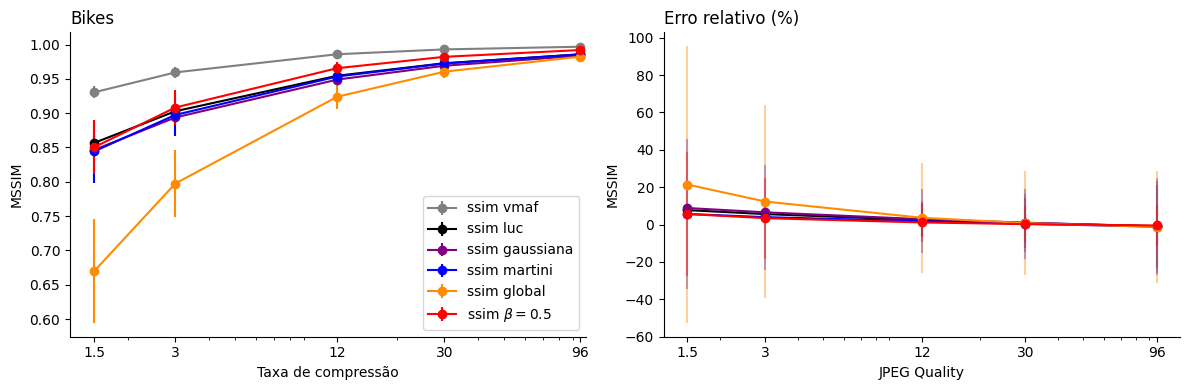

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'Bikes', 0, 5, txs=txs, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 0, 5, txs=txs, ax=axes[1])

plt.tight_layout()
plt.savefig('Bikes.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

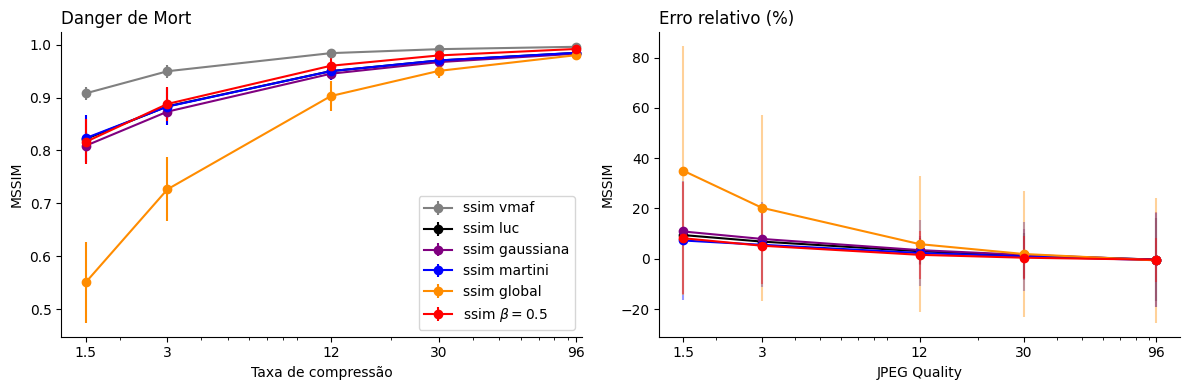

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'Danger de Mort', 5, 10, txs=txs, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 5, 10, txs=txs, ax=axes[1])

plt.tight_layout()
plt.savefig('Danger de Mort.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

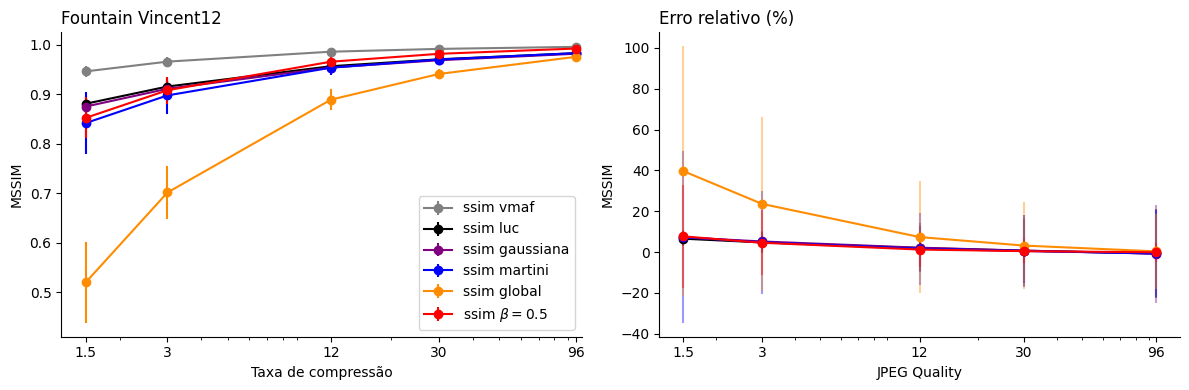

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'Fountain Vincent12', 10, 15, txs=txs, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 10, 15, txs=txs, ax=axes[1])

plt.tight_layout()
plt.savefig('Fountain Vincent12.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

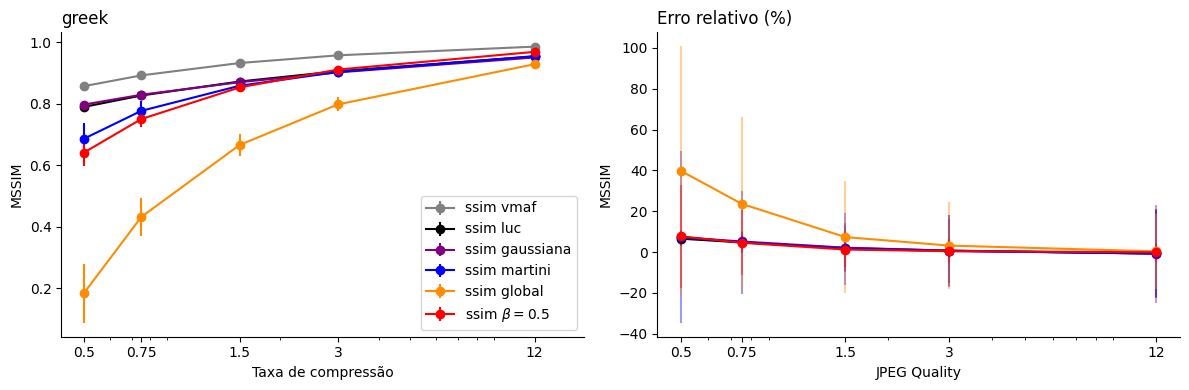

In [34]:
txs_g = [0.5, 0.75, 1.5, 3, 12]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'greek', 15, 20, txs=txs_g, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 10, 15, txs=txs_g, ax=axes[1])

plt.tight_layout()
plt.savefig('greek.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

## Teste para $\beta = 1$

In [35]:
dfs = []

for lf_nome, LFs in d.items():
    path_dir_yuv = f'../lfctest/ce/results/jplm_ssim_estimate_results/{lf_nome}/decoded/yuv/'
    df = calcular_ssim_por_lf(ssim_beta_lf, LFs = LFs, beta = 1)
    dfs.append(df)

ssim_beta1 = pd.concat(dfs)
ssim_beta1.index.name = 'beta1'
ssim_beta1['media'] = ssim_beta1.mean(axis = 1, skipna = True)
ssim_beta1['std'] = ssim_beta1.drop(columns=['media']).std(axis=1, skipna=True)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:05<00:00,  1.05s/it]


In [36]:
dfs = [ssim_df, ssim_beta1]
colors = ['gray', '#ff0000']
labels = ['ssim vmaf', r'ssim $\beta = 1$']

dfs_erro = [ssim_beta1]
colors_erro = ['#ff0000']
labels_erro = [r'ssim $\beta = 1$'] 
txs = [1.5, 3, 12, 30, 96]

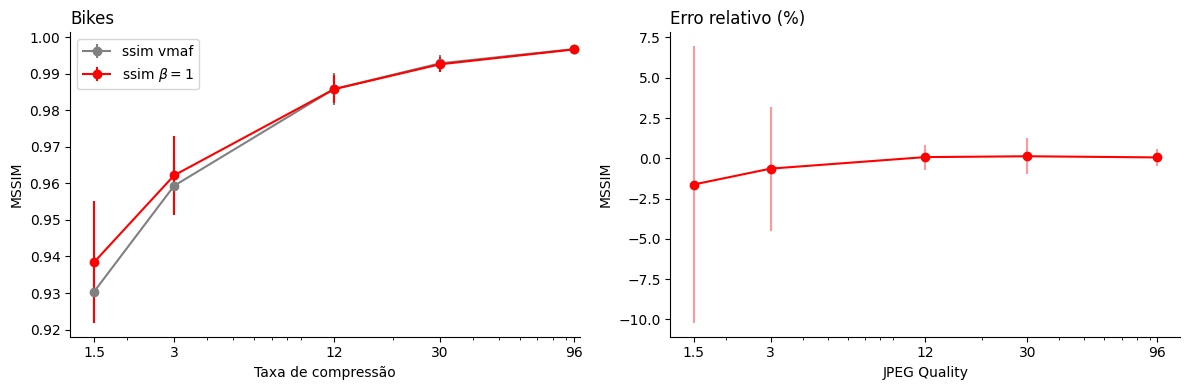

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'Bikes', 0, 5, txs=txs, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 0, 5, txs=txs, ax=axes[1])

plt.tight_layout()
plt.savefig('Bikes_beta1.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

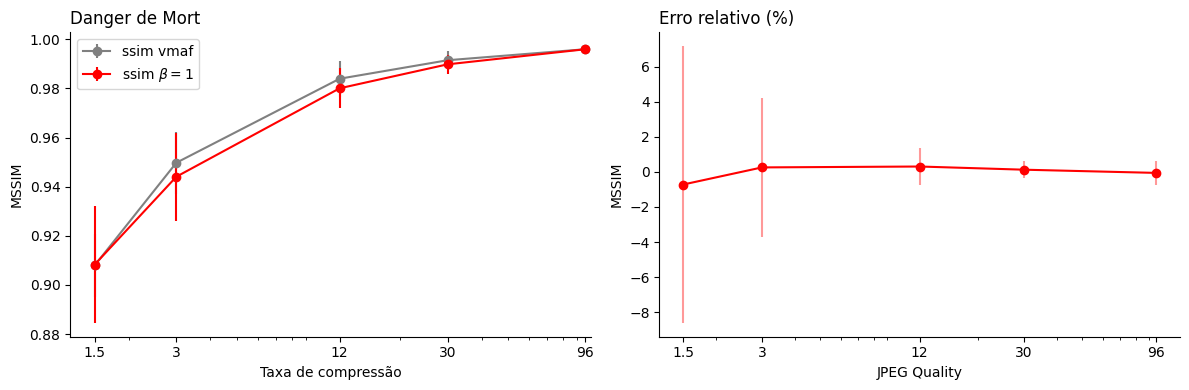

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'Danger de Mort', 5, 10, txs=txs, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 5, 10, txs=txs, ax=axes[1])

plt.tight_layout()
plt.savefig('Danger de Mort_beta1.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

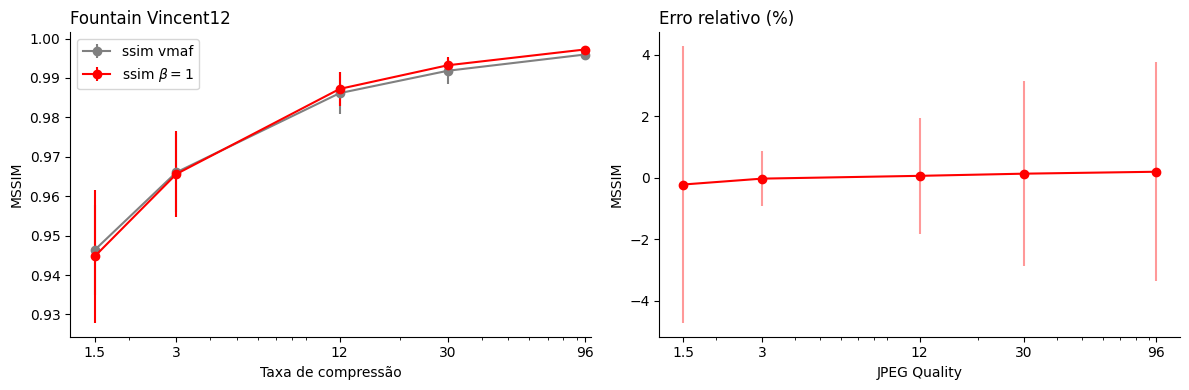

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'Fountain Vincent12', 10, 15, txs=txs, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 10, 15, txs=txs, ax=axes[1])

plt.tight_layout()
plt.savefig('Fontain Vincent12_beta1.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()

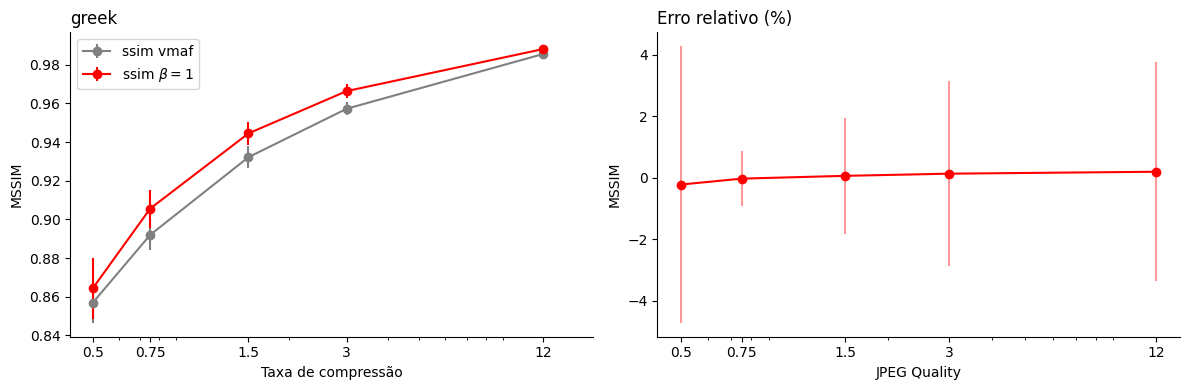

In [40]:
txs_g = [0.5, 0.75, 1.5, 3, 12]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparar_implementacoes(dfs, colors, labels, 'greek', 15, 20, txs=txs_g, ax=axes[0])
comparando_erros(dfs_erro, labels_erro, colors_erro, 10, 15, txs=txs_g, ax=axes[1])

plt.tight_layout()
plt.savefig('greek_beta1.jpeg', dpi = 300, bbox_inches = 'tight')
plt.show()